<a href="https://colab.research.google.com/github/anvithagcs24-stack/AILAB/blob/main/week_8_AILAB_FOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Anvitha G")
print("1WN24CS047")

import itertools

def is_variable(x):
    return isinstance(x, str) and x[0].islower()

def unify(x, y, theta=None):
    if theta is None:
        theta = {}
    if theta == "fail":
        return "fail"
    elif x == y:
        return theta
    elif is_variable(x):
        return unify_var(x, y, theta)
    elif is_variable(y):
        return unify_var(y, x, theta)
    elif isinstance(x, tuple) and isinstance(y, tuple) and len(x) == len(y):
        if x[0] != y[0]:
            return "fail"
        for a, b in zip(x[1:], y[1:]):
            theta = unify(a, b, theta)
            if theta == "fail":
                return "fail"
        return theta
    else:
        return "fail"

def unify_var(var, x, theta):
    if var in theta:
        return unify(theta[var], x, theta)
    elif x in theta:
        return unify(var, theta[x], theta)
    else:
        new_theta = theta.copy()
        new_theta[var] = x
        return new_theta

def subst(theta, expr):
    if isinstance(expr, tuple):
        return tuple(subst(theta, e) for e in expr)
    elif is_variable(expr) and expr in theta:
        return subst(theta, theta[expr])
    else:
        return expr

def standardize_variables(rule, counter):
    premises, conclusion = rule
    mapping = {}
    def replace(expr):
        if isinstance(expr, tuple):
            return tuple(replace(e) for e in expr)
        elif is_variable(expr):
            if expr not in mapping:
                mapping[expr] = f"{expr}_{next(counter)}"
            return mapping[expr]
        return expr
    new_premises = [replace(p) for p in premises]
    new_conclusion = replace(conclusion)
    return new_premises, new_conclusion

def format_atom(atom):
    return f"{atom[0]}({', '.join(atom[1:])})"

def format_rule(rule):
    premises, conclusion = rule
    prem_str = " ∧ ".join(format_atom(p) for p in premises)
    return f"{prem_str} ⇒ {format_atom(conclusion)}"

def fol_fc_ask(facts, rules, alpha):
    kb_facts = set(facts)
    counter = itertools.count(1)
    step = 1

    while True:
        new_facts = set()
        print(f"Iteration - {step}")
        for rule in rules:
            premises, conclusion = standardize_variables(rule, counter)

            def find_substitutions(prem_list, current_theta):
                if not prem_list:
                    yield current_theta
                    return
                first_prem = subst(current_theta, prem_list[0])
                for fact in kb_facts:
                    theta = unify(first_prem, fact, current_theta)
                    if theta != "fail":
                        yield from find_substitutions(prem_list[1:], theta)

            for theta in find_substitutions(premises, {}):
                q_prime = subst(theta, conclusion)
                if q_prime not in kb_facts and q_prime not in new_facts:
                    new_facts.add(q_prime)
                    print(f"Inferred: {format_atom(q_prime)}")
                    phi = unify(q_prime, alpha, {})
                    if phi != "fail":
                        kb_facts.update(new_facts)
                        return True, phi

        if not new_facts:
            return False, None
        kb_facts.update(new_facts)
        step += 1

statements = [
    "As per the law, it is a crime for an American to sell weapons to hostile nations.",
    "Country A, an enemy of America, has some missiles.",
    "All the missiles were sold to it by Robert, who is an American citizen."
]

facts = [
    ("American", "Robert"),
    ("Enemy", "A", "America"),
    ("Owns", "A", "T1"),
    ("Missile", "T1")
]

rules = [
    ([("American", "p"), ("Weapon", "q"), ("Sells", "p", "q", "r"), ("Hostile", "r")], ("Criminal", "p")),
    ([("Missile", "x"), ("Owns", "A", "x")], ("Sells", "Robert", "x", "A")),
    ([("Missile", "x")], ("Weapon", "x")),
    ([("Enemy", "x", "America")], ("Hostile", "x"))
]

query = ("Criminal", "Robert")

print("GIVEN PROBLEM STATEMENTS")
for s in statements:
    print(f"- {s}")

print("\nKNOWLEDGE BASE (FOL REPRESENTATION)")
print("Facts:")
for f in facts:
    print(f"  {format_atom(f)}")

print("\nRules:")
for r in rules:
    print(f"  {format_rule(r)}")

print(f"\nTO PROVE\n  {format_atom(query)}\n")

print("FORWARD CHAINING PROOF")
proved, substitution = fol_fc_ask(facts, rules, query)

print("\nRESULT")
if proved:
    print(f"Query {format_atom(query)} is PROVED! (Substitution: {substitution})")
else:
    print(f"Query {format_atom(query)} CANNOT be proved.")







Anvitha G
1WN24CS047
GIVEN PROBLEM STATEMENTS
- As per the law, it is a crime for an American to sell weapons to hostile nations.
- Country A, an enemy of America, has some missiles.
- All the missiles were sold to it by Robert, who is an American citizen.

KNOWLEDGE BASE (FOL REPRESENTATION)
Facts:
  American(Robert)
  Enemy(A, America)
  Owns(A, T1)
  Missile(T1)

Rules:
  American(p) ∧ Weapon(q) ∧ Sells(p, q, r) ∧ Hostile(r) ⇒ Criminal(p)
  Missile(x) ∧ Owns(A, x) ⇒ Sells(Robert, x, A)
  Missile(x) ⇒ Weapon(x)
  Enemy(x, America) ⇒ Hostile(x)

TO PROVE
  Criminal(Robert)

FORWARD CHAINING PROOF
Iteration - 1
Inferred: Sells(Robert, T1, A)
Inferred: Weapon(T1)
Inferred: Hostile(A)
Iteration - 2
Inferred: Criminal(Robert)

RESULT
Query Criminal(Robert) is PROVED! (Substitution: {})


Anvitha G
1WN24CS047
Initial Knowledge Base: { American(Robert), Enemy(A, America), Missile(T1), Owns(A, T1) }

Rules in Knowledge Base:
  Rule 1: Missile(x) => Weapon(x)
  Rule 2: Missile(x) ^ Owns(A, x) => Sells(Robert, x, A)
  Rule 3: Enemy(x, America) => Hostile(x)
  Rule 4: American(p) ^ Weapon(q) ^ Sells(p, q, r) ^ Hostile(r) => Criminal(p)

Goal to Prove: Criminal(Robert)

--- Iteration 1 ---
  [Derived] Weapon(T1)
     Rule Used : Rule 1 [Missile(x) => Weapon(x)]
     Matched   : Missile(T1)  |  Bindings: {'x': 'T1'}
  [Derived] Sells(Robert, T1, A)
     Rule Used : Rule 2 [Missile(x) ^ Owns(A, x) => Sells(Robert, x, A)]
     Matched   : Missile(T1) ^ Owns(A, T1)  |  Bindings: {'x': 'T1'}
  [Derived] Hostile(A)
     Rule Used : Rule 3 [Enemy(x, America) => Hostile(x)]
     Matched   : Enemy(A, America)  |  Bindings: {'x': 'A'}

--- Iteration 2 ---
  [Derived] Criminal(Robert)
     Rule Used : Rule 4 [American(p) ^ Weapon(q) ^ Sells(p, q, r) ^ Hostile(r) => Criminal(p)]
     Mat

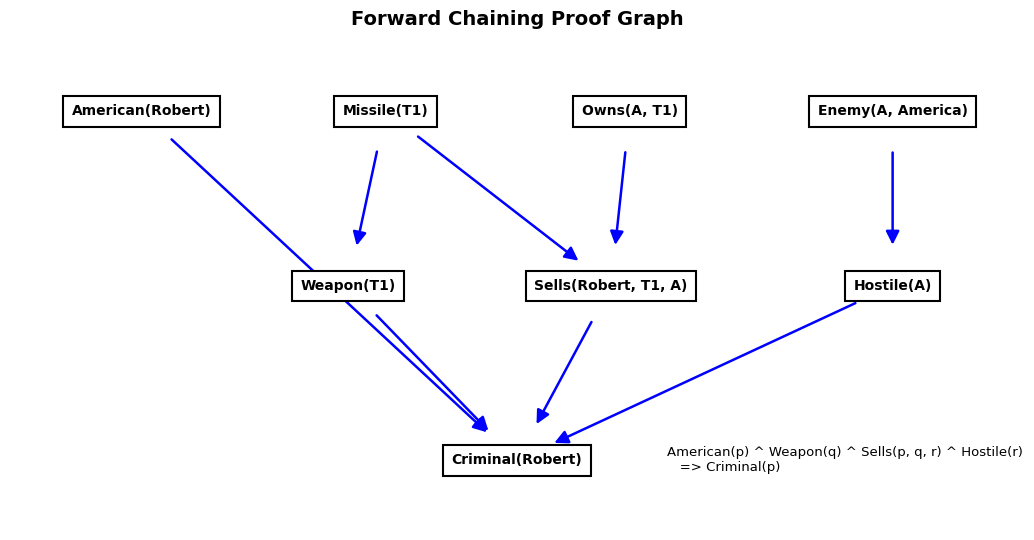

In [2]:
print("Anvitha G")
print("1WN24CS047")

import itertools
import matplotlib.pyplot as plt
import networkx as nx

# ==========================================
# 1. Knowledge Base Setup (Facts & Rules)
# ==========================================

facts = {
    ("American", ("Robert",)),
    ("Missile", ("T1",)),
    ("Owns", ("A", "T1")),
    ("Enemy", ("A", "America")),
}

rules = [
    # Rule 1: Missile(x) => Weapon(x)
    ([("Missile", ("x",))], ("Weapon", ("x",))),
    # Rule 2: Missile(x) ^ Owns(A, x) => Sells(Robert, x, A)
    ([("Missile", ("x",)), ("Owns", ("A", "x"))], ("Sells", ("Robert", "x", "A"))),
    # Rule 3: Enemy(x, America) => Hostile(x)
    ([("Enemy", ("x", "America"))], ("Hostile", ("x",))),
    # Rule 4: American(p) ^ Weapon(q) ^ Sells(p, q, r) ^ Hostile(r) => Criminal(p)
    (
        [
            ("American", ("p",)),
            ("Weapon", ("q",)),
            ("Sells", ("p", "q", "r")),
            ("Hostile", ("r",)),
        ],
        ("Criminal", ("p",)),
    ),
]

goal = ("Criminal", ("Robert",))

# ==========================================
# 2. Helper Functions
# ==========================================


def is_variable(term):
  return term[0].islower()


def format_pred(pred):
  name, args = pred
  return f"{name}({', '.join(args)})"


def format_rule(premises, conclusion):
  prem_str = " ^ ".join(format_pred(p) for p in premises)
  return f"{prem_str} => {format_pred(conclusion)}"


def unify(pattern, fact, substitution):
  if pattern[0] != fact[0] or len(pattern[1]) != len(fact[1]):
    return None
  new_sub = substitution.copy()
  for p_term, f_term in zip(pattern[1], fact[1]):
    if is_variable(p_term):
      if p_term in new_sub:
        if new_sub[p_term] != f_term:
          return None
      else:
        new_sub[p_term] = f_term
    else:
      if p_term != f_term:
        return None
  return new_sub


def substitute(predicate, substitution):
  name, args = predicate
  new_args = tuple(substitution.get(arg, arg) for arg in args)
  return (name, new_args)


# ==========================================
# 3. Forward Chaining + Graph Builder
# ==========================================


def solve_and_plot(facts, rules, goal):
  # Print Initial Knowledge Base in ONE line
  kb_one_line = ", ".join(format_pred(f) for f in sorted(facts))
  print(f"Initial Knowledge Base: {{ {kb_one_line} }}")

  # Print Rules in Knowledge Base
  print("\nRules in Knowledge Base:")
  for idx, (prem, conc) in enumerate(rules, 1):
    print(f"  Rule {idx}: {format_rule(prem, conc)}")

  print(f"\nGoal to Prove: {format_pred(goal)}\n" + "=" * 55)

  derived_edges = []
  iteration = 1
  goal_reached = False

  while not goal_reached:
    new_inferred = set()
    print(f"\n--- Iteration {iteration} ---")

    for rule_idx, (premises, conclusion) in enumerate(rules, 1):
      for fact_combo in itertools.product(facts, repeat=len(premises)):
        sub = {}
        matched = True

        for premise, fact in zip(premises, fact_combo):
          sub = unify(premise, fact, sub)
          if sub is None:
            matched = False
            break

        if matched:
          inferred_fact = substitute(conclusion, sub)
          if inferred_fact not in facts and inferred_fact not in new_inferred:
            new_inferred.add(inferred_fact)

            # Record edges for the proof graph
            inf_str = format_pred(inferred_fact)
            for f in fact_combo:
              derived_edges.append((format_pred(f), inf_str))

            # Print derivation details including the rule used
            premise_str = " ^ ".join(format_pred(f) for f in fact_combo)
            print(f"  [Derived] {inf_str}")
            rule_str = format_rule(premises, conclusion)
            print(f"     Rule Used : Rule {rule_idx} [{rule_str}]")
            print(f"     Matched   : {premise_str}  |  Bindings: {sub}")

    if not new_inferred:
      print("  No new facts inferred.")
      break

    facts.update(new_inferred)

    if goal in facts:
      goal_reached = True
      print("\n" + "=" * 55)
      print(f"SUCCESS: Proved {format_pred(goal)}!")
      print("=" * 55 + "\n")
      break

    iteration += 1

  # ==========================================
  # 4. Plot the Forward Chaining Proof Graph
  # ==========================================
  G = nx.DiGraph()
  G.add_edges_from(derived_edges)

  # Node positions structured cleanly in 3 tiers (Initial -> Intermediate -> Goal)
  pos = {
      "American(Robert)": (0.0, 2.0),
      "Missile(T1)": (1.3, 2.0),
      "Owns(A, T1)": (2.6, 2.0),
      "Enemy(A, America)": (4.0, 2.0),
      "Weapon(T1)": (1.1, 1.0),
      "Sells(Robert, T1, A)": (2.5, 1.0),
      "Hostile(A)": (4.0, 1.0),
      "Criminal(Robert)": (2.0, 0.0),
  }

  plt.figure(figsize=(11, 5.5))

  # Draw rectangular boxes for each predicate node
  ax = plt.gca()
  nx.draw_networkx_edges(
      G,
      pos,
      ax=ax,
      arrows=True,
      arrowsize=20,
      edge_color="blue",
      width=1.8,
      node_size=3500,
  )

  for node, (x, y) in pos.items():
    if node in G.nodes():
      ax.text(
          x,
          y,
          node,
          ha="center",
          va="center",
          fontsize=10,
          fontweight="bold",
          bbox=dict(
              boxstyle="square,pad=0.6",
              facecolor="white",
              edgecolor="black",
              linewidth=1.5,
          ),
      )

  # Add the final rule annotation at the bottom right like your slide
  plt.text(
      2.8,
      0.0,
      "American(p) ^ Weapon(q) ^ Sells(p, q, r) ^ Hostile(r)\n"
      "   => Criminal(p)",
      fontsize=9.5,
      va="center",
  )

  plt.xlim(-0.7, 4.7)
  plt.ylim(-0.4, 2.4)
  plt.title(
      "Forward Chaining Proof Graph", fontsize=14, fontweight="bold", pad=12
  )
  plt.axis("off")
  plt.tight_layout()
  plt.show()


# Execute everything
solve_and_plot(facts, rules, goal)